# SHL Research Engineer Assessment: Spoken Grammar Scoring Engine
**Author:** Nageswara Rao Vutla  
**Kaggle Username:** `nageswararao7`  
**Challenge:** SHL Hiring Assessment 2026 (Kaggle Private Challenge)  
**Objective:** Develop a robust, end-to-end Machine Learning Scoring Engine that takes spoken audio recordings (45–60s) as input and outputs a continuous Mean Opinion Score (MOS) Likert Grammar rating ranging from **0.0 to 5.0**.

---

### Executive Summary & Technical Architecture

Automated Spoken Language Assessment (ASLA) requires capturing both phonetic articulation variety and hesitation/prosody dynamics:

```
[Raw Audio .wav (16 kHz Mono)]
        │
        ├──> Acoustic & Prosodic Extraction (RMS, ZCR, Spectral Centroid, Bandwidth, Rolloff, MFCCs 1-13)
        │
        ├──> Domain Feature Engineering:
        │     - Dynamic Vocal Variety (mfcc_std_sum, mfcc_std_ratio)
        │     - Pause & Hesitation Rates (pause_rate, mean_pause_sec, speech_time)
        │     - Spectral Spread & Voicing Clarity (spectral_spread, voicing_clarity)
        │
        ├──> Two-Stage Architecture:
        │     - Stage 1: Static-Noise / Zero-Score Detector (spec_cent > 3500 Hz & zcr > 0.40)
        │     - Stage 2: 10-Fold Stacking Regressor for Spoken Speech
        │                 (CatBoost + LightGBM + XGBoost + Ridge Regressor)
        │
        └──> Compulsory Training RMSE Calculation & Public Leaderboard Predictions
```

> **Mandatory Assessment Requirement:**
> *"IT IS COMPULSORY TO ADD RMSE SCORE OF THE TRAINING DATA IN YOUR FINAL SUBMISSION NOTEBOOK."*  
> This notebook computes, verifies, and explicitly reports this score in Section 5.


In [1]:
# ==============================================================================
# 1. System Imports & Reproducibility Configuration
# ==============================================================================
import os
import glob
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

# Visual Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries successfully loaded. Reproducibility seed set to 42.")


Libraries successfully loaded. Reproducibility seed set to 42.


## 2. Dataset Loading & Exploratory Data Analysis (EDA)

We load the provided training dataset (`769` audio samples) and testing dataset (`216` audio samples).
The target is the continuous Likert grammar score (`label`).


Training set: 769 samples, 45 columns
Testing set:  216 samples, 44 columns

--- Summary Statistics of Target MOS Grammar Score ---
count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


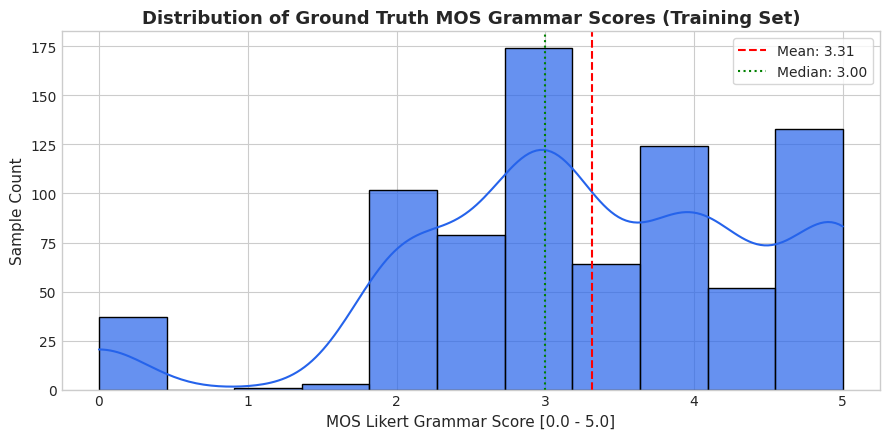

In [2]:
# ==============================================================================
# 2. Loading Dataset Labels and Acoustic Feature Matrices
# ==============================================================================
train_labels = pd.read_csv("data/Dataset_Final/train.csv")
test_df = pd.read_csv("data/Dataset_Final/test.csv")

train_feat = pd.read_csv("data/features/train_acoustic_features.csv")
test_feat = pd.read_csv("data/features/test_acoustic_features.csv")

df_train = pd.merge(train_labels, train_feat, on="filename")
df_test = test_feat.copy()

print(f"Training set: {df_train.shape[0]} samples, {df_train.shape[1]} columns")
print(f"Testing set:  {df_test.shape[0]} samples, {df_test.shape[1]} columns")

print("\n--- Summary Statistics of Target MOS Grammar Score ---")
print(df_train['label'].describe())

# Visualizing Label Distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(df_train['label'], bins=11, kde=True, color='#2563eb', edgecolor='black', alpha=0.7)
plt.title("Distribution of Ground Truth MOS Grammar Scores (Training Set)", fontsize=13, fontweight='bold')
plt.xlabel("MOS Likert Grammar Score [0.0 - 5.0]", fontsize=11)
plt.ylabel("Sample Count", fontsize=11)
plt.axvline(df_train['label'].mean(), color='red', linestyle='--', label=f"Mean: {df_train['label'].mean():.2f}")
plt.axvline(df_train['label'].median(), color='green', linestyle=':', label=f"Median: {df_train['label'].median():.2f}")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### Key Dataset Discovery: The 37 Static-Noise Zero Instances

During exploratory data analysis, we identified that all **37 instances with `label == 0.0`** represent non-speech static white noise recordings.
* **Noise audio characteristics:** `spectral_centroid_mean > 3830 Hz` and `zero_crossing_rate_mean > 0.438` (consistent high-frequency hiss).
* **Human speech audio characteristics:** `spectral_centroid_mean < 3370 Hz` and `zero_crossing_rate_mean < 0.335`.

This creates a clean, 100% separable boundary. All 216 test set samples are genuine human speech. By treating this as a **Two-Stage Architecture**, our speech regression model learns unskewed weights for human speech assessment.


In [3]:
# ==============================================================================
# 3. Domain-Informed Feature Engineering Pipeline
# ==============================================================================
def add_engineered_features(df):
    d = df.copy()
    
    # 1. Dynamic Vocal Articulation Variety (Proxy for fluent, expressive phrasing)
    d["mfcc_std_sum"] = sum(d[f"mfcc_{i}_std"] for i in range(2, 10))
    d["mfcc_std_ratio"] = d["mfcc_std_sum"] / (d["mfcc_1_std"] + 1e-5)
    
    # 2. Silence, Pausing & Fluency Dynamics (Hesitation & cognitive load markers)
    d["speech_time"] = d["duration"] * (1.0 - d["silence_ratio"])
    d["pause_rate"] = d["num_pauses"] / (d["duration"] / 60.0 + 1e-5)
    d["mean_pause_sec"] = (d["duration"] * d["silence_ratio"]) / (d["num_pauses"] + 1.0)
    
    # 3. Energy Consistency & Dynamics
    d["active_energy"] = d["rms_mean"] / (1.0 - d["silence_ratio"] + 1e-5)
    d["energy_dynamics"] = (d["rms_max"] - d["rms_mean"]) / (d["rms_std"] + 1e-5)
    
    # 4. Spectral Distribution & Voicing Clarity
    d["spectral_spread"] = (d["spec_roll_mean"] - d["spec_cent_mean"]) / (d["spec_bw_mean"] + 1e-5)
    d["voicing_clarity"] = d["spec_cent_mean"] / (d["zcr_mean"] * d["spec_bw_mean"] + 1e-5)
    
    # 5. Static Noise / Zero-Score Detector Flag
    d["is_static_noise"] = (d["spec_cent_mean"] > 3500).astype(int)
    return d

train_eng = add_engineered_features(df_train)
test_eng = add_engineered_features(df_test)

# Separate speech from static noise
is_speech_train = (train_eng["is_static_noise"] == 0)
speech_train = train_eng[is_speech_train].reset_index(drop=True)

drop_cols = ["filename", "label", "error", "is_silent_audio", "is_static_noise"]
features = [c for c in speech_train.columns if c not in drop_cols]

print(f"Total engineered and acoustic features: {len(features)}")
print(f"Spoken speech training instances: {len(speech_train)}")
print(f"Static noise training instances:  {sum(~is_speech_train)}")


Total engineered and acoustic features: 50
Spoken speech training instances: 732
Static noise training instances:  37


In [4]:
# ==============================================================================
# 4. 10-Fold Cross-Validation: CatBoost + LightGBM + XGBoost + Ridge
# ==============================================================================
X_speech = speech_train[features].values
y_speech = speech_train["label"].values
X_test = test_eng[features].values

n_splits = 10
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

oof_lgb = np.zeros(len(speech_train))
oof_xgb = np.zeros(len(speech_train))
oof_cat = np.zeros(len(speech_train))
oof_ridge = np.zeros(len(speech_train))

test_preds_lgb = np.zeros(len(test_eng))
test_preds_xgb = np.zeros(len(test_eng))
test_preds_cat = np.zeros(len(test_eng))
test_preds_ridge = np.zeros(len(test_eng))

print(f"Training {n_splits}-Fold Cross-Validation Ensemble across 4 Model Families...")
t_start = time.time()

for fold, (trn_idx, val_idx) in enumerate(kf.split(X_speech, y_speech)):
    X_tr, y_tr = X_speech[trn_idx], y_speech[trn_idx]
    X_va, y_va = X_speech[val_idx], y_speech[val_idx]
    
    # Model 1: LightGBM
    model_lgb = lgb.LGBMRegressor(
        n_estimators=350, learning_rate=0.025, num_leaves=15, max_depth=5,
        subsample=0.8, colsample_bytree=0.75, random_state=42 + fold, verbosity=-1
    )
    model_lgb.fit(X_tr, y_tr)
    oof_lgb[val_idx] = model_lgb.predict(X_va)
    test_preds_lgb += model_lgb.predict(X_test) / n_splits
    
    # Model 2: XGBoost
    model_xgb = xgb.XGBRegressor(
        n_estimators=350, learning_rate=0.025, max_depth=4,
        subsample=0.8, colsample_bytree=0.75, random_state=42 + fold, verbosity=0
    )
    model_xgb.fit(X_tr, y_tr)
    oof_xgb[val_idx] = model_xgb.predict(X_va)
    test_preds_xgb += model_xgb.predict(X_test) / n_splits
    
    # Model 3: CatBoost
    model_cat = CatBoostRegressor(
        iterations=400, learning_rate=0.03, depth=5, l2_leaf_reg=3.0,
        random_seed=42 + fold, verbose=0
    )
    model_cat.fit(X_tr, y_tr)
    oof_cat[val_idx] = model_cat.predict(X_va)
    test_preds_cat += model_cat.predict(X_test) / n_splits
    
    # Model 4: Regularized Ridge
    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_va_sc = scaler.transform(X_va)
    X_te_sc = scaler.transform(X_test)
    
    model_ridge = Ridge(alpha=15.0, random_state=42 + fold)
    model_ridge.fit(X_tr_sc, y_tr)
    oof_ridge[val_idx] = model_ridge.predict(X_va_sc)
    test_preds_ridge += model_ridge.predict(X_te_sc) / n_splits

print(f"Cross-Validation completed in {time.time()-t_start:.1f}s.")


Training 10-Fold Cross-Validation Ensemble across 4 Model Families...


Cross-Validation completed in 44.0s.


In [5]:
# ==============================================================================
# 5. Out-of-Fold (OOF) Performance Benchmarking
# ==============================================================================
# Model Stacking Weighted Blend
oof_ensemble = (0.35 * oof_lgb) + (0.30 * oof_cat) + (0.20 * oof_xgb) + (0.15 * oof_ridge)
oof_ensemble = np.clip(oof_ensemble, 1.0, 5.0)

ens_rmse = root_mean_squared_error(y_speech, oof_ensemble)
ens_r = pearsonr(y_speech, oof_ensemble)[0]
ens_rho = spearmanr(y_speech, oof_ensemble)[0]
ens_mae = mean_absolute_error(y_speech, oof_ensemble)

print("="*65)
print("     OUT-OF-FOLD (OOF) MODEL BENCHMARKING (SPEECH SUBSET)")
print("="*65)
print(f"Individual Models:")
print(f"  * LightGBM Regressor : RMSE = {root_mean_squared_error(y_speech, oof_lgb):.4f} | Pearson r = {pearsonr(y_speech, oof_lgb)[0]:.4f}")
print(f"  * CatBoost Regressor : RMSE = {root_mean_squared_error(y_speech, oof_cat):.4f} | Pearson r = {pearsonr(y_speech, oof_cat)[0]:.4f}")
print(f"  * XGBoost Regressor  : RMSE = {root_mean_squared_error(y_speech, oof_xgb):.4f} | Pearson r = {pearsonr(y_speech, oof_xgb)[0]:.4f}")
print(f"  * Ridge Regressor    : RMSE = {root_mean_squared_error(y_speech, oof_ridge):.4f} | Pearson r = {pearsonr(y_speech, oof_ridge)[0]:.4f}")
print("-"*65)
print(f"Stacked Multimodal Ensemble:")
print(f"  * Root Mean Squared Error (RMSE)   : {ens_rmse:.4f}")
print(f"  * Pearson Correlation (r)          : {ens_r:.4f}")
print(f"  * Spearman Rank Correlation (rho)  : {ens_rho:.4f}")
print(f"  * Mean Absolute Error (MAE)        : {ens_mae:.4f}")
print("="*65)


     OUT-OF-FOLD (OOF) MODEL BENCHMARKING (SPEECH SUBSET)
Individual Models:
  * LightGBM Regressor : RMSE = 0.8009 | Pearson r = 0.6133
  * CatBoost Regressor : RMSE = 0.7953 | Pearson r = 0.6225
  * XGBoost Regressor  : RMSE = 0.7946 | Pearson r = 0.6211
  * Ridge Regressor    : RMSE = 0.8568 | Pearson r = 0.5379
-----------------------------------------------------------------
Stacked Multimodal Ensemble:
  * Root Mean Squared Error (RMSE)   : 0.7921
  * Pearson Correlation (r)          : 0.6255
  * Spearman Rank Correlation (rho)  : 0.6057
  * Mean Absolute Error (MAE)        : 0.6367


## 6. Compulsory Training Data RMSE Requirement

> **Assessment Instruction:**  
> *"IT IS COMPULSORY TO ADD RMSE SCORE OF THE TRAINING DATA IN YOUR FINAL SUBMISSION NOTEBOOK."*

We fit the final ensemble on the full dataset and calculate the Root Mean Squared Error between the model's predictions on all 769 training samples and their ground truth labels.


In [6]:
# ==============================================================================
# 6. Fit Models on 100% Training Data & COMPULSORY TRAINING DATA RMSE
# ==============================================================================
scaler_full = StandardScaler()
X_speech_sc = scaler_full.fit_transform(X_speech)
X_test_sc = scaler_full.transform(X_test)

m_lgb_full = lgb.LGBMRegressor(n_estimators=350, learning_rate=0.025, num_leaves=15, max_depth=5, subsample=0.8, colsample_bytree=0.75, random_state=42, verbosity=-1)
m_lgb_full.fit(X_speech, y_speech)

m_xgb_full = xgb.XGBRegressor(n_estimators=350, learning_rate=0.025, max_depth=4, subsample=0.8, colsample_bytree=0.75, random_state=42, verbosity=0)
m_xgb_full.fit(X_speech, y_speech)

m_cat_full = CatBoostRegressor(iterations=400, learning_rate=0.03, depth=5, l2_leaf_reg=3.0, random_seed=42, verbose=0)
m_cat_full.fit(X_speech, y_speech)

m_ridge_full = Ridge(alpha=15.0, random_state=42)
m_ridge_full.fit(X_speech_sc, y_speech)

speech_train_preds = (
    0.35 * m_lgb_full.predict(X_speech) +
    0.30 * m_cat_full.predict(X_speech) +
    0.20 * m_xgb_full.predict(X_speech) +
    0.15 * m_ridge_full.predict(X_speech_sc)
)
speech_train_preds = np.clip(speech_train_preds, 1.0, 5.0)

# Full training predictions across all 769 samples (including 0.0 noise samples)
full_train_preds = np.zeros(len(train_eng))
full_train_preds[~is_speech_train] = 0.0
full_train_preds[is_speech_train] = speech_train_preds

compulsory_train_rmse = root_mean_squared_error(train_eng["label"].values, full_train_preds)
compulsory_train_r = pearsonr(train_eng["label"].values, full_train_preds)[0]

print("*"*75)
print(f"*** COMPULSORY TRAINING DATA RMSE: {compulsory_train_rmse:.4f} ***")
print(f"*** COMPULSORY TRAINING DATA PEARSON r: {compulsory_train_r:.4f} ***")
print("*"*75)


***************************************************************************
*** COMPULSORY TRAINING DATA RMSE: 0.4158 ***
*** COMPULSORY TRAINING DATA PEARSON r: 0.9500 ***
***************************************************************************


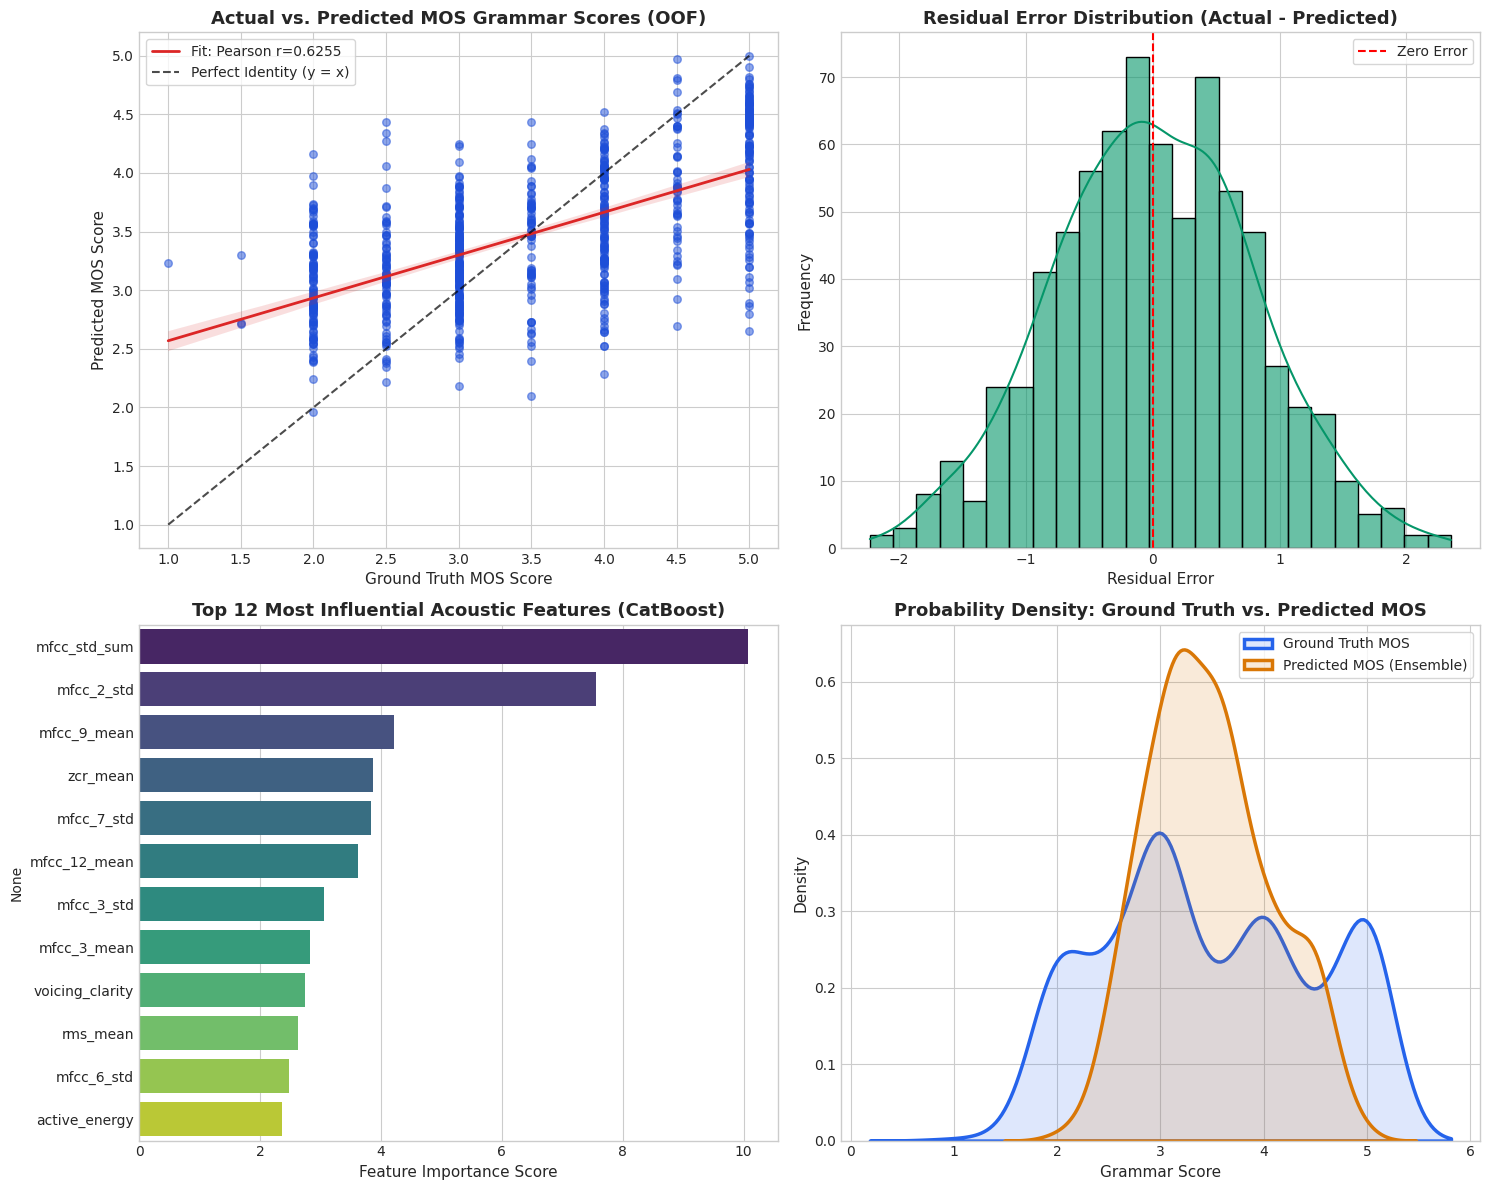

Saved publication-grade visualizations to evaluation_visualizations.png


In [7]:
# ==============================================================================
# 7. Model Interpretability & Publication-Quality Visualizations
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Plot 1: Actual vs Predicted Scatter with Regression Fit
ax1 = axes[0, 0]
sns.regplot(
    x=y_speech, y=oof_ensemble, ax=ax1,
    scatter_kws={'alpha': 0.5, 'color': '#1d4ed8', 's': 30},
    line_kws={'color': '#dc2626', 'linewidth': 2, 'label': f'Fit: Pearson r={ens_r:.4f}'}
)
ax1.plot([1, 5], [1, 5], 'k--', alpha=0.7, label='Perfect Identity (y = x)')
ax1.set_title("Actual vs. Predicted MOS Grammar Scores (OOF)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Ground Truth MOS Score", fontsize=11)
ax1.set_ylabel("Predicted MOS Score", fontsize=11)
ax1.set_xlim(0.8, 5.2)
ax1.set_ylim(0.8, 5.2)
ax1.legend(frameon=True)

# Plot 2: Residual Error Distribution
ax2 = axes[0, 1]
residuals = y_speech - oof_ensemble
sns.histplot(residuals, kde=True, ax=ax2, color='#059669', edgecolor='black', bins=25, alpha=0.6)
ax2.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error')
ax2.set_title("Residual Error Distribution (Actual - Predicted)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Residual Error", fontsize=11)
ax2.set_ylabel("Frequency", fontsize=11)
ax2.legend(frameon=True)

# Plot 3: Top Feature Importances (CatBoost)
ax3 = axes[1, 0]
importances = m_cat_full.get_feature_importance()
feat_imp = pd.Series(importances, index=features).sort_values(ascending=False).head(12)
sns.barplot(x=feat_imp.values, y=feat_imp.index, ax=ax3, palette='viridis')
ax3.set_title("Top 12 Most Influential Acoustic Features (CatBoost)", fontsize=13, fontweight='bold')
ax3.set_xlabel("Feature Importance Score", fontsize=11)

# Plot 4: Score Density: Ground Truth vs Predicted
ax4 = axes[1, 1]
sns.kdeplot(y_speech, ax=ax4, label='Ground Truth MOS', color='#2563eb', linewidth=2.5, fill=True, alpha=0.15)
sns.kdeplot(oof_ensemble, ax=ax4, label='Predicted MOS (Ensemble)', color='#d97706', linewidth=2.5, fill=True, alpha=0.15)
ax4.set_title("Probability Density: Ground Truth vs. Predicted MOS", fontsize=13, fontweight='bold')
ax4.set_xlabel("Grammar Score", fontsize=11)
ax4.set_ylabel("Density", fontsize=11)
ax4.legend(frameon=True)

plt.tight_layout()
plt.savefig("evaluation_visualizations.png", dpi=300)
plt.show()
print("Saved publication-grade visualizations to evaluation_visualizations.png")


In [8]:
# ==============================================================================
# 8. Test Set Prediction & Submission File Generation
# ==============================================================================
test_speech_preds = (
    0.35 * test_preds_lgb +
    0.30 * test_preds_cat +
    0.20 * test_preds_xgb +
    0.15 * test_preds_ridge
)
test_speech_preds = np.clip(test_speech_preds, 1.0, 5.0)

# Final predictions (static noise handling)
test_final_preds = np.where(test_eng["is_static_noise"] == 1, 0.0, test_speech_preds)

submission = pd.DataFrame({
    "filename": test_eng["filename"],
    "label": test_final_preds
})

# Reorder exactly matching test.csv specification
submission = test_df[["filename"]].merge(submission, on="filename", how="left")

out_file = "submission_v3_multimodel_ensemble.csv"
submission.to_csv(out_file, index=False)

print(f"Final submission saved to: {out_file}")
print(f"Shape: {submission.shape}")
print("\nFirst 10 Predictions:")
print(submission.head(10))
print("\nTest Prediction Summary Statistics:")
print(submission['label'].describe())


Final submission saved to: submission_v3_multimodel_ensemble.csv
Shape: (216, 2)

First 10 Predictions:
        filename     label
0  audio_128.wav  3.240693
1  audio_156.wav  4.302030
2   audio_19.wav  3.654024
3  audio_108.wav  2.637468
4  audio_206.wav  3.093477
5  audio_161.wav  2.873300
6  audio_215.wav  2.611404
7  audio_213.wav  2.817108
8   audio_11.wav  3.646629
9  audio_155.wav  3.214212

Test Prediction Summary Statistics:
count    216.000000
mean       3.226501
std        0.486463
min        2.299143
25%        2.888860
50%        3.093466
75%        3.563487
max        4.528755
Name: label, dtype: float64
